# [실습] 트리 앙상블과 SHAP — 더 강한 모델, 그리고 그 모델 설명하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 5 실습. 해지 요인을 경영진에 어떻게 보고할까?

**필수 머신러닝 · Chapter 5**

| Part | 주제 |
| --- | --- |
| Part 1 | 트리를 모으면 강해진다 |
| Part 2 | 모델이 무엇을 보는가: 피처 중요도와 SHAP |
| Part 3 | SHAP을 읽을 때의 함정 |
| Part 4 | 경영진과 CS팀에 보고하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 경영기획팀 (Chapter 1 CS팀 의뢰의 후속)
> **목적**: CS팀의 해지 예측 모델을 경영진 보고에 쓰려 한다. 경영진은 "누가 해지할 것인가"보다 "왜 해지하는가, 무엇을 바꿔야 하는가"를 알고 싶어 한다.
> **제약**: 보고서에 적은 요인을 근거로 요금제나 계약 정책을 바꾸는 결정이 내려질 수 있다. 틀린 요인을 적으면 비용이 든다.
> **질문**: 해지에 영향을 주는 요인은 무엇이며, 그 요인을 바꾸면 해지가 줄어드는가?

## 이 실습의 질문

> **경영진에 보고할 해지 요인 세 가지는 무엇이고, 그중 "바꾸면 해지가 줄어든다"고 말할 수 있는 것은 몇 개인가? 그리고 CS팀 상담원에게 줄 고객별 위험 신호는 어떻게 만들 것인가?**

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |
| **먼저 예상하기** | 결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다 |

## 준비

Chapter 1의 Telco 데이터 `WA_Fn-UseC_-Telco-Customer-Churn.csv`를 이 노트북과 같은 폴더에 두세요. SHAP 라이브러리가 없다면 먼저 설치합니다(`pip install shap`).

이 실습은 앙상블 모델을 교차검증으로 여러 번 학습하므로, 몇몇 셀은 실행에 1분 안팎이 걸립니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# [환경] 그래프 한글 글꼴 등록 (같은 폴더의 fonts/NanumGothic-Regular.ttf)
import os
import matplotlib.font_manager as fm
for _p in ["fonts/NanumGothic-Regular.ttf", "../fonts/NanumGothic-Regular.ttf", "NanumGothic-Regular.ttf"]:
    if os.path.exists(_p):
        fm.fontManager.addfont(_p)
        plt.rcParams["font.family"] = fm.FontProperties(fname=_p).get_name()
        break
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 트리를 모으면 강해진다

## 1-1. 준비

**[제공]** 데이터를 불러와 Chapter 1과 같은 방법(80 : 20, `random_state=42`, `stratify`)으로 나눕니다. 누적 요금(`TotalCharges`)은 Chapter 4에서 확인한 대로 해지 시점에 멈춘 스냅샷 값이라 쓰지 않습니다. 고객 ID(`customerID`)도 피처에서 뺍니다.

| 이름 | 뜻 |
| --- | --- |
| `num_cols` | 숫자 피처 3개: `tenure`(가입 기간), `MonthlyCharges`(월 요금), `SeniorCitizen`(고령 여부 0/1) |
| `cat_cols` | 범주 피처 15개 (계약 유형, 인터넷 종류, 결제 방법 등) |
| `features` | 두 목록을 합친 피처 18개 |

In [3]:
# [제공] 데이터 준비
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["target"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])

num_cols = ["tenure", "MonthlyCharges", "SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn", "target", "TotalCharges"]]
features = num_cols + cat_cols
y_train, y_test = train_df["target"], test_df["target"]
print(len(train_df), len(test_df), "| 피처 수", len(features), "| 학습용 해지율", round(y_train.mean(), 3))

5634 1409 | 피처 수 18 | 학습용 해지율 0.265


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `make_pipe(모델, scale=True)` | 전처리(숫자 열 스케일링, 범주 열 원핫 인코딩)와 모델을 묶은 파이프라인을 만든다. 트리 계열은 `scale=False` |
| `evaluate_model(이름, 파이프라인)` | 5겹 교차검증 ROC AUC, 학습용 전체로 학습한 뒤의 평가용 ROC AUC·PR AUC, 학습용 ROC AUC를 결과표에 남기고, 학습된 파이프라인을 돌려준다 |
| `compare(이름 A, 모델 A, 이름 B, 모델 B)` | 두 모델을 같은 5겹으로 평가해 fold별 차이를 보여 준다 (Chapter 4) |
| `show_log()` | 결과표를 보여 준다 |

In [4]:
# [제공] 실습 도구
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

def make_pipe(clf, scale=True):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])

def evaluate_model(name, model):
    s = cross_val_score(model, train_df[features], y_train, cv=cv, scoring="roc_auc")
    model.fit(train_df[features], y_train)
    p_te = model.predict_proba(test_df[features])[:, 1]
    p_tr = model.predict_proba(train_df[features])[:, 1]
    row = {"모델": name, "교차검증 AUC": f"{s.mean():.3f} ± {s.std():.3f}",
           "평가용 AUC": round(roc_auc_score(y_test, p_te), 3),
           "평가용 PR AUC": round(average_precision_score(y_test, p_te), 3),
           "학습용 AUC": round(roc_auc_score(y_train, p_tr), 3)}
    results.append(row)
    print(row)
    return model

def compare(name_a, model_a, name_b, model_b):
    s_a = cross_val_score(model_a, train_df[features], y_train, cv=cv, scoring="roc_auc")
    s_b = cross_val_score(model_b, train_df[features], y_train, cv=cv, scoring="roc_auc")
    diff = s_b - s_a
    print(f"{name_a}: {s_a.round(3)} | 평균 {s_a.mean():.3f} ± {s_a.std():.3f}")
    print(f"{name_b}: {s_b.round(3)} | 평균 {s_b.mean():.3f} ± {s_b.std():.3f}")
    print(f"fold별 차이 (B - A): {diff.round(3)} | 평균 차이 {diff.mean():+.3f}")
    print()

def show_log():
    return pd.DataFrame(results)

## 1-2. 지니 계수 손으로 계산하기

결정트리는 "나눈 뒤 섞임이 가장 많이 줄어드는 질문"을 고릅니다. 섞임은 지니 계수 $G = 2p(1-p)$로 잽니다($p$는 해지 비율).

**[직접 작성]** 학습용 데이터에서 다음을 계산해 출력하세요.

1. 함수 `gini(p)`: $2p(1-p)$를 돌려준다
2. 나누기 전의 지니 계수
3. "월 단위 계약인가"(`Contract == "Month-to-month"`)로 나눈 뒤 두 상자의 고객 수, 해지 비율, 지니 계수
4. 고객 수로 가중 평균한 나눈 뒤의 지니 계수 $G_{\text{split}}$와 감소량 $\Delta G$

<details><summary>힌트</summary>

```python
m = train_df["Contract"] == "Month-to-month"
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
g_split = m.mean() * gini(p_left) + (~m).mean() * gini(p_right)
```
</details>

In [5]:
def gini(p):
    return 2 * p * (1 - p)

p_all = train_df["target"].mean()
print(f"나누기 전: p={p_all:.4f} | 지니 계수 G={gini(p_all):.4f}")

m = train_df["Contract"] == "Month-to-month"
n_left, n_right = int(m.sum()), int((~m).sum())
p_left = train_df.loc[m, "target"].mean()
p_right = train_df.loc[~m, "target"].mean()
print(f"월 단위 계약({n_left:,}명): 해지율 {p_left:.4f} | 지니 {gini(p_left):.4f}")
print(f"그 외({n_right:,}명):        해지율 {p_right:.4f} | 지니 {gini(p_right):.4f}")

g_split = (n_left * gini(p_left) + n_right * gini(p_right)) / len(train_df)
print(f"나눈 뒤 가중 평균 G_split={g_split:.4f} | 감소량 ΔG={gini(p_all) - g_split:.4f}")

나누기 전: p=0.2654 | 지니 계수 G=0.3899
월 단위 계약(3,102명): 해지율 0.4275 | 지니 0.4895
그 외(2,532명):        해지율 0.0667 | 지니 0.1246
나눈 뒤 가중 평균 G_split=0.3255 | 감소량 ΔG=0.0644


> **[판단]** 월 단위 상자의 지니 계수는 나누기 전보다 커졌습니다. 그런데도 전체로는 섞임이 줄어든 이유는 무엇인가요?
>
> 나의 답:

월 단위 상자 하나의 지니 계수는 0.4895로 나누기 전(0.3899)보다 **커졌습니다**(더 섞였습니다). 그런데도 전체로는 섞임이 줄었습니다. 월 단위 상자(3,102명, 해지율 42.8%)와 그 외 상자(2,532명, 6.7%)가 **서로 아주 다른** 집단으로 갈렸기 때문입니다. 지니 계수는 상자 **안**의 섞임만 재므로, 한 상자가 섞여도 다른 상자가 거의 순수하면 가중 평균은 낮아집니다. 계산으로는 0.4895×3,102/5,634 + 0.1246×2,532/5,634 = 0.3255이고 감소량 ΔG는 0.0644입니다. 즉 트리의 판단은 "각 상자가 모두 순수해지는가"가 아니라 **"나눈 뒤 전체가 얼마나 순수해지는가"**입니다.


## 1-3. 트리 하나의 한계

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다.

> **[판단]** 예상: 깊이 제한 없이 끝까지 자란 트리의 학습용 AUC와 평가용 AUC는 각각 얼마쯤일까요? 깊이 3 트리(평가용 약 0.82)보다 나을까요?
>
> 나의 답:

예상: 깊이 제한 없는 트리는 **학습용 AUC 1.000**, 평가용 AUC **0.65~0.70**으로, 깊이 3(0.818)보다 평가 성능이 **나쁠 것**이라고 봤습니다. 학습용은 완벽하지만 새 고객에는 약할 것으로 예상했습니다.


**[직접 작성]** `evaluate_model`로 결정트리 세 개(깊이 3, 깊이 6, 깊이 제한 없음)를 평가하세요. 트리는 스케일링이 필요 없으므로 `make_pipe(..., scale=False)`, `random_state=42`를 씁니다.

<details><summary>힌트</summary>

`evaluate_model("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False))`. 깊이 제한이 없으면 `max_depth=None`(기본값)입니다.
</details>

In [6]:
tree3 = evaluate_model("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False))
tree6 = evaluate_model("트리 깊이 6", make_pipe(DecisionTreeClassifier(max_depth=6, random_state=42), scale=False))
tree_full = evaluate_model("트리 깊이 제한 없음", make_pipe(DecisionTreeClassifier(random_state=42), scale=False))

{'모델': '트리 깊이 3', '교차검증 AUC': '0.817 ± 0.006', '평가용 AUC': 0.818, '평가용 PR AUC': 0.556, '학습용 AUC': 0.824}


{'모델': '트리 깊이 6', '교차검증 AUC': '0.824 ± 0.011', '평가용 AUC': 0.835, '평가용 PR AUC': 0.617, '학습용 AUC': 0.865}


{'모델': '트리 깊이 제한 없음', '교차검증 AUC': '0.658 ± 0.013', '평가용 AUC': 0.669, '평가용 PR AUC': 0.39, '학습용 AUC': 1.0}


> **[판단]** 예상은 맞았나요? 깊이 제한 없는 트리의 학습용 AUC와 평가용 AUC의 차이를 "편향"과 "분산" 중 무엇으로 설명할 수 있나요? 깊이 3 트리는 어느 쪽의 문제가 더 클까요?
>
> 나의 답:

예상이 맞았습니다. 깊이 제한 없는 트리는 학습용 AUC **1.000**(완전히 외움), 평가용 **0.669**로 깊이 3(0.818)보다 오히려 **나쁩니다**. 학습용과 평가용의 0.33 차이는 **분산(variance)** 문제입니다. 데이터의 세세한 잡음까지 외워서, 조금만 다른 새 고객에는 그 규칙이 맞지 않습니다. 깊이 3 트리는 학습용 0.824·평가용 0.818로 둘이 붙어 있고, 두 쪽 모두 0.82에서 막혀 있어 **편향(bias)** 문제가 더 큽니다. 이 데이터에서는 편향을 조금 줄이는 쪽(깊이 6, 0.835)이 이득이었습니다.


## 1-4. 트리들을 서로 다르게: 배깅과 랜덤포레스트

**[제공]** 전처리만 한 학습용·평가용 데이터(`X_tr_t`, `X_te_t`)를 만듭니다. 이 절과 1-6에서 씁니다.

In [7]:
# [제공] 전처리한 데이터 (트리용: 스케일링 없음)
pre_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr_t = pd.DataFrame(pre_tree.fit_transform(train_df[features]), columns=pre_tree.get_feature_names_out())
X_te_t = pd.DataFrame(pre_tree.transform(test_df[features]), columns=pre_tree.get_feature_names_out())
print(X_tr_t.shape, X_te_t.shape)

(5634, 44) (1409, 44)


**[직접 작성]** 부트스트랩 표본 20개를 만들고, 표본마다 깊이 3 트리 두 가지를 학습해 **첫 질문(맨 위 노드)에 쓰인 피처**를 세어 보세요.

- 배깅: `DecisionTreeClassifier(max_depth=3, random_state=b)`
- 피처 후보 제한(랜덤포레스트 방식): `DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b)`

<details><summary>힌트</summary>

```python
rng = np.random.RandomState(42)
idx = rng.randint(0, len(X_tr_t), len(X_tr_t))       # 복원 추출로 고른 행 번호
t = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
root = X_tr_t.columns[t.tree_.feature[0]]             # 첫 질문에 쓰인 피처 이름
```
</details>

In [8]:
rng = np.random.RandomState(42)
first_bag, first_rf = [], []
for b in range(20):
    idx = rng.randint(0, len(X_tr_t), len(X_tr_t))
    t1 = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
    t2 = DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
    first_bag.append(X_tr_t.columns[t1.tree_.feature[0]])
    first_rf.append(X_tr_t.columns[t2.tree_.feature[0]])

print("배깅 20회의 첫 질문:")
print(pd.Series(first_bag).value_counts())
print()
print("피처 후보 제한(√) 20회의 첫 질문:")
print(pd.Series(first_rf).value_counts())

배깅 20회의 첫 질문:
cat__Contract_Month-to-month    20
Name: count, dtype: int64

피처 후보 제한(√) 20회의 첫 질문:
num__tenure                                  3
cat__Contract_Month-to-month                 3
cat__TechSupport_No internet service         2
cat__PaymentMethod_Electronic check          2
cat__TechSupport_No                          2
cat__Contract_One year                       1
cat__DeviceProtection_No internet service    1
cat__InternetService_Fiber optic             1
num__MonthlyCharges                          1
cat__Contract_Two year                       1
cat__PaperlessBilling_No                     1
cat__StreamingMovies_No internet service     1
cat__StreamingTV_No internet service         1
Name: count, dtype: int64


> **[판단]** 두 방법의 첫 질문은 어떻게 다른가요? 교안 1-3의 식 $\rho\sigma^2 + (1-\rho)\sigma^2/B$와 연결해, 피처 후보를 제한하면 왜 평균의 효과가 커지는지 설명해 보세요.
>
> 나의 답:

배깅(표본만 바꿈)은 20번 모두 **월 단위 계약**을 첫 질문으로 골랐습니다(20/20). 피처 후보를 √(44개 중 7개)로 제한하면 첫 질문이 13종류로 **흩어졌고**, 가장 많이 나온 것도 3/20(가입 기간, 월 단위 계약)에 그칩니다. 교안의 식 ρσ² + (1-ρ)σ²/B에서, 배깅은 트리들이 서로 비슷해서(ρ가 큼) **ρσ² 항이 줄지 않고**, B를 늘려도 두 번째 항만 줄어 한계가 있습니다. 피처 후보를 제한하면 트리 사이의 상관 ρ가 작아져 **첫째 항 자체가 작아지고**, 그래서 평균의 분산이 더 크게 줄어듭니다. 다만 이번 데이터처럼 압도적으로 강한 변수(월 단위 계약)가 있으면, 무작위로 후보를 제한하는 것이 그 변수를 놓칠 확률도 만듭니다(20번 중 3번만 첫 질문으로 선택).


**[직접 작성]** `evaluate_model`로 랜덤포레스트 두 개를 평가하세요. 둘 다 `n_estimators=300, random_state=42, n_jobs=-1`이고, 하나는 기본값, 하나는 잎에 최소 20명(`min_samples_leaf=20`)입니다.

In [9]:
rf = evaluate_model("랜덤포레스트", make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), scale=False))
rf_leaf = evaluate_model("랜덤포레스트 (잎 최소 20명)",
                         make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1), scale=False))

{'모델': '랜덤포레스트', '교차검증 AUC': '0.813 ± 0.012', '평가용 AUC': 0.813, '평가용 PR AUC': 0.596, '학습용 AUC': 1.0}


{'모델': '랜덤포레스트 (잎 최소 20명)', '교차검증 AUC': '0.846 ± 0.009', '평가용 AUC': 0.84, '평가용 PR AUC': 0.637, '학습용 AUC': 0.875}


> **[판단]** 기본값 랜덤포레스트의 학습용 AUC와 평가용 AUC를 보세요. "앙상블이니까 과적합하지 않는다"는 말은 맞나요? 잎의 최소 고객 수를 늘리면 무엇이 달라지나요?
>
> 나의 답:

기본값 랜덤포레스트는 학습용 AUC **1.000**, 평가용 **0.813**입니다. "앙상블이니까 과적합하지 않는다"는 말은 **틀렸습니다**. 각 트리가 깊이 제한 없이 자라 잎에 1명씩 들어가므로, 학습용은 완벽히 외우고 평가용은 깊이 3 트리(0.818)보다도 나쁩니다. 잎의 최소 고객 수를 20명으로 늘리면 학습용 0.875·평가용 **0.840**으로 개선되고, 교차검증도 0.813 → **0.846**으로 올라 7개 모델 중 상위권이 됩니다. 트리 하나하나의 분산을 줄이는 것이 앙상블의 효과를 살리는 조건입니다.


## 1-5. 부스팅: 트리를 더할수록

**[직접 작성]** 경사 부스팅 모델 `GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)`를 `X_tr_t`로 학습하고, 트리를 1, 10, 50, 100, 200, 500개 더한 시점의 학습용 AUC와 평가용 AUC를 표로 출력하세요.

<details><summary>힌트</summary>

`staged_predict_proba`는 트리를 하나씩 더할 때마다의 확률을 차례로 돌려줍니다.
```python
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in [1, 10, 50, 100, 200, 500]:
        ...  # p_tr[:, 1], p_te[:, 1]로 AUC 계산
```
</details>

In [10]:
gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42).fit(X_tr_t, y_train)

rows = []
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in (1, 10, 50, 100, 200, 500):
        rows.append({"트리 수": i, "학습용 AUC": round(roc_auc_score(y_train, p_tr[:, 1]), 3),
                     "평가용 AUC": round(roc_auc_score(y_test, p_te[:, 1]), 3)})
gb_staged = pd.DataFrame(rows)
gb_staged

,트리 수,학습용 AUC,평가용 AUC
0,1,0.824,0.818
1,10,0.849,0.839
2,50,0.868,0.844
3,100,0.879,0.843
4,200,0.895,0.838
5,500,0.930,0.828


> **[판단]** 트리 수를 늘릴 때 학습용과 평가용 AUC는 각각 어떻게 움직이나요? 랜덤포레스트의 트리 수와 무엇이 다른가요? 이 표를 보고 트리 수를 고르면 어떤 문제가 있을까요? (Chapter 4 3-1)
>
> 나의 답:

트리를 늘릴 때 **학습용 AUC는 계속 오르고**(0.824 → 0.930), **평가용 AUC는 50개(0.844)에서 정점을 찍고 내려갑니다**(100개 0.843, 200개 0.838, 500개 0.828). 랜덤포레스트는 트리를 늘려도 평가 성능이 거의 변하지 않고(포화), 부스팅은 트리를 늘릴수록 **과적합**이 진행됩니다. 그래서 "평가용 AUC가 가장 높은 트리 수"를 이 표에서 고르면, 그 평가용 점수를 이미 보고 고른 것이 되어 Chapter 4의 규칙(설정은 학습용 안에서만)을 어깁니다. 트리 수는 **교차검증**으로 골라야 하고, 이 표는 "왜 500개를 그대로 쓰면 안 되는가"를 보여 주는 진단으로 읽어야 합니다.


## 1-6. 더 강한 모델은 얼마나 강한가

**[직접 작성]** 두 가지를 하세요.

1. `evaluate_model`로 로지스틱 회귀(`make_pipe(LogisticRegression(max_iter=3000))`)와 경사 부스팅 기본값(`GradientBoostingClassifier(random_state=42)`, `scale=False`)을 평가하고, 부스팅 파이프라인을 `gbm_model`에 저장한 뒤 `show_log()`로 결과표를 보세요.
2. `compare`로 "트리 깊이 3 vs 경사 부스팅", "로지스틱 회귀 vs 경사 부스팅"을 비교하세요.

In [11]:
logit = evaluate_model("로지스틱 회귀", make_pipe(LogisticRegression(max_iter=3000)))
gbm_model = evaluate_model("경사 부스팅 (기본값)", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))
show_log()

{'모델': '로지스틱 회귀', '교차검증 AUC': '0.845 ± 0.012', '평가용 AUC': 0.839, '평가용 PR AUC': 0.63, '학습용 AUC': 0.848}


{'모델': '경사 부스팅 (기본값)', '교차검증 AUC': '0.848 ± 0.011', '평가용 AUC': 0.843, '평가용 PR AUC': 0.654, '학습용 AUC': 0.879}


,모델,교차검증 AUC,평가용 AUC,평가용 PR AUC,학습용 AUC
0,트리 깊이 3,0.817 ± 0.006,0.818,0.556,0.824
1,트리 깊이 6,0.824 ± 0.011,0.835,0.617,0.865
2,트리 깊이 제한 없음,0.658 ± 0.013,0.669,0.390,1.000
3,랜덤포레스트,0.813 ± 0.012,0.813,0.596,1.000
4,랜덤포레스트 (잎 최소 20명),0.846 ± 0.009,0.840,0.637,0.875
5,로지스틱 회귀,0.845 ± 0.012,0.839,0.630,0.848
6,경사 부스팅 (기본값),0.848 ± 0.011,0.843,0.654,0.879


> **[판단]** 앙상블은 트리 하나보다 분명히 나은가요? 로지스틱 회귀보다는 나은가요? Chapter 4의 기준(fold별 차이와 편차)으로 판단하세요. 성능만 본다면 어느 모델을 고르겠습니까?
>
> 나의 답:

분명히 낫지는 않습니다. 교차검증 AUC는 경사 부스팅 **0.848±0.011**, 로지스틱 회귀 0.845±0.012, 잎 20명 랜덤포레스트 0.846±0.009로 **셋이 구별되지 않습니다**. 트리 하나(깊이 3, 0.817)보다는 0.03 정도 낫지만, fold 편차(0.011)의 3배 수준입니다. 로지스틱 회귀와 비교하면 차이가 0.003으로 편차보다 작습니다. 성능만 본다면 **로지스틱 회귀**를 고르겠습니다. 해석이 쉽고 학습·배포가 가볍고, 차이가 없기 때문입니다.


> **[판단]** 그런데도 이 실습은 Part 2에서 경사 부스팅 모델을 설명에 씁니다. 성능이 비슷한데도 부스팅을 쓸 이유가 있다면 무엇일까요? (교안 1-7, 2-5)
>
> 나의 답:

성능이 비슷한데도 부스팅을 쓰는 이유는 **설명의 재료** 때문입니다. (1) 부스팅은 변수 사이의 상호작용(예: "월 단위 계약이면서 가입 6개월 이내")을 스스로 잡아, SHAP으로 그 상호작용을 고객 단위로 분해할 수 있습니다. (2) 로지스틱 회귀에서 계수 하나를 읽으면 "다른 조건이 같을 때"의 효과인데, 이 데이터는 변수끼리 강하게 얽혀 있어(월 요금↔광케이블 상관 0.785) 그 해석이 실제 고객에게 잘 맞지 않습니다. (3) 부스팅의 SHAP은 고객 한 명 단위로 "왜 이 고객이 위험한가"를 보여 줘 CS팀이 바로 쓸 수 있습니다. 즉 0.003의 성능 차이가 아니라 **설명 가능성**이 선택 이유입니다.


---
# Part 2. 모델이 무엇을 보는가

이제부터 `gbm_model`(경사 부스팅 기본값)을 설명합니다.

## 2-1. 피처 중요도 두 가지

**[직접 작성]** 두 가지 중요도의 상위 5개를 출력하세요.

1. **불순도 중요도**: `gbm_model.named_steps["clf"].feature_importances_` (전처리 뒤의 열 이름은 `gbm_model.named_steps["pre"].get_feature_names_out()`)
2. **순열 중요도**: `permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)` (원래 피처 18개 기준)

<details><summary>힌트</summary>

결과를 `pd.Series(값, index=이름).sort_values(ascending=False).head(5)`로 정리하면 보기 쉽습니다. 순열 중요도의 값은 `.importances_mean`입니다.
</details>

In [12]:
clf = gbm_model.named_steps["clf"]
names = gbm_model.named_steps["pre"].get_feature_names_out()

imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False)
print("[불순도 중요도] 상위 5개")
print(imp.head(5).round(4))

perm = permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)
perm_s = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)
print()
print("[순열 중요도] 상위 5개 (평가용 ROC AUC 감소)")
print(perm_s.head(5).round(4))

[불순도 중요도] 상위 5개
cat__Contract_Month-to-month        0.3855
num__tenure                         0.1820
num__MonthlyCharges                 0.1012
cat__InternetService_Fiber optic    0.0896
cat__OnlineSecurity_No              0.0693
dtype: float64



[순열 중요도] 상위 5개 (평가용 ROC AUC 감소)
Contract           0.0760
tenure             0.0722
InternetService    0.0088
MonthlyCharges     0.0074
OnlineSecurity     0.0058
dtype: float64


> **[판단]** 두 중요도의 순위는 어떻게 다른가요? 두 중요도로는 답할 수 없는 질문을 두 가지 적어 보세요. (예: 가입 기간이 길면 해지 확률이 오르나, 내리나?)
>
> 나의 답:

두 중요도의 순위는 꽤 다릅니다. 불순도 중요도는 월 단위 계약(0.386) > 가입 기간(0.182) > 월 요금(0.101) > 광케이블(0.090) 순이고, 순열 중요도는 **계약 0.076 > 가입 기간 0.072**로 압도적이며 나머지는 0.001~0.009로 급격히 작아집니다. 불순도 중요도는 트리가 나눌 때 얼마나 섞임을 줄였는지만 세므로, **범주가 많은 변수**(원핫으로 열이 여러 개인 계약)에 유리하고 상관된 변수끼리 중요도를 나눠 갖습니다. 순열 중요도는 "이 변수를 섞으면 평가 성능이 얼마나 떨어지는가"라서 상관된 변수가 남아 있으면 중요도가 낮게 나옵니다.
두 중요도로 답할 수 없는 질문: ① **"가입 기간이 길면 해지 확률이 오르나, 내리나?"**(방향), ② **"월 요금 90달러 이상에서만 위험이 커지나?"**(구간·임계점), ③ **"이 고객 한 명은 왜 위험한가?"**(개인별 이유).


## 2-2. SHAP 값 계산하고 가산성 확인하기

**[직접 작성]**

1. 평가용 데이터를 `gbm_model`의 전처리로 바꿔 `X_test_t`(열 이름이 붙은 DataFrame)를 만드세요.
2. `shap.TreeExplainer`로 `shap_values`(고객 수 × 피처 수)와 `base_value`(기준값)를 계산하세요.
3. 평가용 첫 고객에서 "기준값 + 기여도 합"과 모델의 로그 오즈 출력(`decision_function`)이 같은지 확인하세요.

<details><summary>힌트</summary>

```python
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
```
</details>

In [13]:
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())

explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0]) if np.ndim(explainer.expected_value) else float(explainer.expected_value)
print("shap_values 모양:", np.shape(shap_values), "| base_value(로그 오즈):", round(base_value, 4))

i = 0
additive = base_value + shap_values[i].sum()
decision = float(gbm.decision_function(X_test_t.iloc[[i]])[0])
print(f"첫 고객: base+Σ기여도={additive:.6f} | decision_function={decision:.6f} | 차이={additive - decision:.2e}")
print("확률로 바꾸면:", round(1 / (1 + np.exp(-base_value)), 3), "| 학습용 해지율:", round(y_train.mean(), 3))

shap_values 모양: (1409, 44) | base_value(로그 오즈): -1.5942
첫 고객: base+Σ기여도=-3.938199 | decision_function=-3.938199 | 차이=2.66e-15
확률로 바꾸면: 0.169 | 학습용 해지율: 0.265


> **[판단]** 기준값을 확률로 바꾸면 얼마인가요? ($p = 1/(1 + e^{-z})$) 학습용 해지율(약 0.265)과 같나요? 다르다면 왜 다를까요? (교안 3-2)
>
> 나의 답:

기준값(로그 오즈 -1.5942)을 확률로 바꾸면 **0.169**이고, 학습용 해지율 0.265와 다릅니다. 이유는 base_value가 **평가용 데이터의 평균 예측**이 아니라 모델이 학습 과정에서 출발한 **전체 기준선**(트리 앙상블의 초기값과 평균 기여도 구조)이기 때문입니다. SHAP의 base_value는 "모델 출력의 평균"이고, 확률로 바꾸면 로짓의 평균(0.169)이 되어 확률의 평균(0.265)과 일치하지 않습니다(로짓↔확률 변환이 비선형). 그리고 이 기준값은 평가용 표본의 평균 예측과도 조금 다를 수 있습니다. 중요한 것은 **기준값 + 기여도 합 = 모델 출력**이 정확히 성립한다는 점입니다(차이 2.7e-15로 가산성 확인).


## 2-3. 전체 그림: bar와 beeswarm

**[직접 작성]** 피처별 기여도 **절댓값의 평균**을 계산해 상위 8개를 출력하고, `shap.summary_plot(shap_values, X_test_t, max_display=10)`로 beeswarm 그래프를 그리세요.

[기여도 절댓값 평균] 상위 8개
cat__Contract_Month-to-month           0.6392
num__tenure                            0.5065
cat__OnlineSecurity_No                 0.2419
num__MonthlyCharges                    0.2259
cat__TechSupport_No                    0.2073
cat__InternetService_Fiber optic       0.1987
cat__Contract_Two year                 0.1687
cat__PaymentMethod_Electronic check    0.1676
dtype: float64


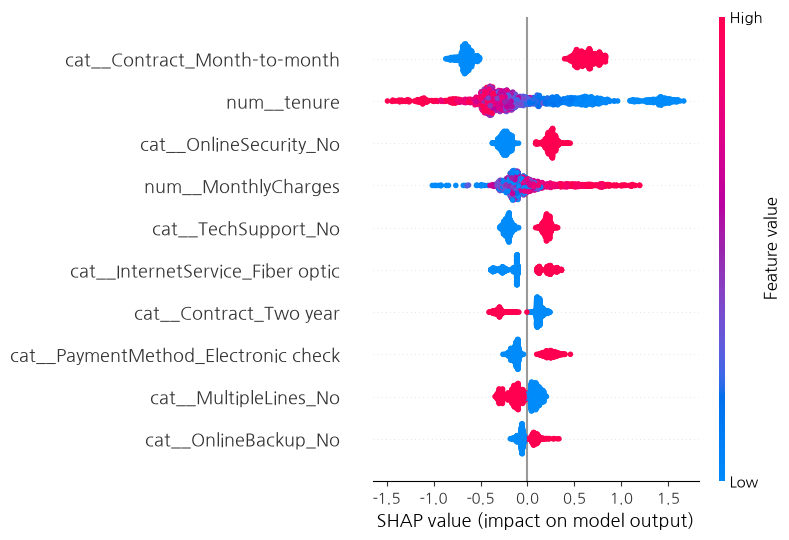

In [14]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_t.columns).sort_values(ascending=False)
print("[기여도 절댓값 평균] 상위 8개")
print(mean_abs.head(8).round(4))

shap.summary_plot(shap_values, X_test_t, max_display=10, show=False)
plt.tight_layout()
plt.show()

> **[판단]** beeswarm 그래프에서 월 단위 계약(`cat__Contract_Month-to-month`)과 가입 기간(`num__tenure`)의 점은 각각 어느 쪽에 모여 있나요? 색(빨강 = 값이 큼)과 함께 읽어, "이 값이 크면 모델은 해지 확률을 올리는가, 내리는가"를 두 피처에 대해 적으세요.
>
> 나의 답:

월 단위 계약: 빨간 점(값 1)이 **오른쪽(+)** 에 몰려 있고, 파란 점(0)은 0 근처나 왼쪽에 있습니다. 즉 **월 단위 계약이면 모델은 해지 확률을 올립니다**(평균 +0.64). 가입 기간: 빨간 점(기간이 김)은 **왼쪽(-)** 에, 파란 점(기간이 짧음)은 **오른쪽(+)** 에 몰려 있습니다. 즉 **가입 기간이 짧을수록 해지 확률을 올리고, 길수록 내립니다**. 두 변수 모두 흩어진 폭이 커서 고객마다 효과가 다르다는 것도 보입니다(월 단위 계약이라도 다른 조건이 좋으면 위험이 상쇄됩니다).


## 2-4. 어디서 꺾이는가: dependence

**[직접 작성]** 가입 기간과 월 요금의 기여도를 구간별로 평균해 표로 출력하세요.

- 가입 기간 구간: `[0, 6, 12, 24, 48, 72]` (개월)
- 월 요금 구간: `[0, 40, 70, 90, 120]` (달러)

<details><summary>힌트</summary>

```python
tenure_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__tenure")])
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
tenure_shap.groupby(tenure_bin.values, observed=True).mean()
```
</details>

In [15]:
tenure_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__tenure")], index=X_test_t.index)
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
print("[가입 기간 구간별 기여도 평균]")
print(tenure_shap.groupby(tenure_bin.values, observed=True).mean().round(3).rename("SHAP (로그 오즈)"))

charge_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__MonthlyCharges")], index=X_test_t.index)
charge_bin = pd.cut(X_test_t["num__MonthlyCharges"], [0, 40, 70, 90, 120], include_lowest=True)
print()
print("[월 요금 구간별 기여도 평균]")
print(charge_shap.groupby(charge_bin.values, observed=True).mean().round(3).rename("SHAP (로그 오즈)"))

[가입 기간 구간별 기여도 평균]
(-0.001, 6.0]    0.951
(6.0, 12.0]      0.325
(12.0, 24.0]    -0.027
(24.0, 48.0]    -0.283
(48.0, 72.0]    -0.579
Name: SHAP (로그 오즈), dtype: float64

[월 요금 구간별 기여도 평균]
(-0.001, 40.0]   -0.164
(40.0, 70.0]     -0.143
(70.0, 90.0]     -0.049
(90.0, 120.0]     0.459
Name: SHAP (로그 오즈), dtype: float64


> **[판단]** 가입 기간의 기여도는 어느 구간에서 가장 크고, 어디쯤에서 0을 지나나요? 월 요금은 "높을수록 해지"라고 말할 수 있나요, 아니면 특정 금액 위에서만 그런가요? 이 결과를 CS팀에 어떤 행동 지침으로 전하겠습니까?
>
> 나의 답:

가입 기간의 기여도는 **0~6개월 구간에서 평균 +0.951**로 가장 크고, 6~12개월 +0.325, 12~24개월 **-0.027**로 0을 지나, 24~48개월 -0.283, 48~72개월 -0.579로 내려갑니다. 즉 **가입 1년 안쪽이 가장 위험하고, 2년을 넘기면 오히려 해지를 막는 요인**이 됩니다. 월 요금은 "높을수록 해지"라고 단정할 수 없습니다. 40달러 이하 -0.164, 40~70달러 -0.143, 70~90달러 -0.049, **90달러 이상 +0.459**로, **90달러를 넘어설 때만** 위험을 올립니다. 40~70달러 구간은 오히려 위험을 낮춥니다.
CS팀 지침으로는 이렇게 전하겠습니다. "가입 1년 안쪽 고객은 2년 계약 전환·온보딩 콜을 우선하고, 월 90달러 이상 고객은 요금제 상담을 함께 제안한다. 가입 2년이 넘고 요금이 90달러 미만이면 해지 위험이 낮으므로 접촉 우선순위를 낮춘다." 이는 **상관과 구간**의 정보이며, "바꾸면 줄어든다"는 인과는 3-3에서 따로 확인해야 합니다.


## 2-5. 고객 한 명: waterfall

**[직접 작성]** 평가용 고객 중 모델이 해지 확률을 **가장 높게** 매긴 고객을 찾아, 그 고객의 해지 확률과 가입 기간·계약·월 요금을 출력하고, waterfall 그래프를 그리세요.

<details><summary>힌트</summary>

```python
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i], feature_names=list(X_test_t.columns)))
```
</details>

가장 위험한 고객: 5178-LMXOP
해지 확률: 0.917
      tenure        Contract  MonthlyCharges InternetService
3380       1  Month-to-month            95.1     Fiber optic


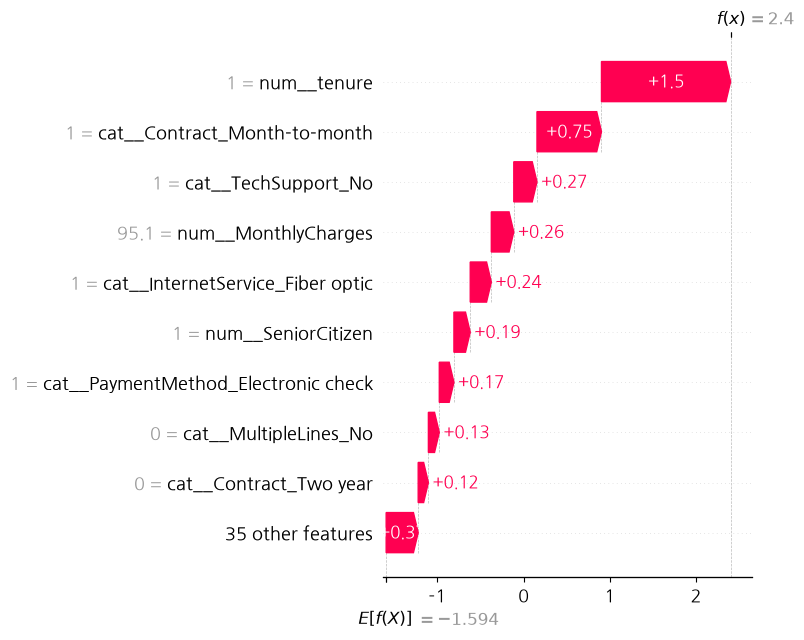

In [16]:
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
print("가장 위험한 고객:", test_df["customerID"].iloc[i])
print(f"해지 확률: {prob[i]:.3f}")
print(test_df[["tenure", "Contract", "MonthlyCharges", "InternetService"]].iloc[[i]])

shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i].values, feature_names=list(X_test_t.columns)),
                     max_display=10, show=False)
plt.tight_layout()
plt.show()

> **[판단]** 이 고객에게 전화할 CS팀 상담원에게, 이 그래프를 한 문장으로 바꿔 전해 보세요. 그 문장에 "이것을 바꾸면 해지하지 않는다"는 뜻이 들어가지 않도록 주의하세요.
>
> 나의 답:

이 고객(5178-LMXOP, 해지 확률 0.917)은 **가입 1개월, 월 단위 계약, 월 95달러, 광케이블**입니다. 상담원에게는 이렇게 전하겠습니다.
"이 고객은 가입한 지 한 달 된 월 단위 계약 고객이고 월 요금이 95달러로 높습니다. 모델이 보기에 이 세 가지가 해지 위험을 크게 올리고 있어, 첫 달 이탈 위험이 높은 상태입니다. 2년 약정 전환과 요금제 조정을 함께 상담해 주세요."
"이것을 바꾸면 해지하지 않는다"는 표현은 넣지 않았습니다. 이 그래프는 **모델이 그렇게 판단한 이유**이지, 개입의 효과를 확인한 실험이 아니기 때문입니다.


---
# Part 3. SHAP을 읽을 때의 함정

## 3-1. 상관 피처가 기여도를 나눠 가진다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 월 요금과 광케이블 인터넷은 정보가 많이 겹치는 피처입니다(광케이블 요금이 비쌈).

> **[판단]** 예상: 월 요금을 모델에서 빼고 다시 학습하면, 광케이블 인터넷(`cat__InternetService_Fiber optic`)의 기여도 절댓값 평균은 지금(2-3)보다 커질까요, 작아질까요, 그대로일까요?
>
> 나의 답:

예상: 월 요금을 빼면 광케이블의 기여도는 **커질 것**입니다. 두 변수가 상관 0.785로 강하게 얽혀 있어, 지금은 광케이블의 몫 일부를 월 요금이 가져가고 있다고 봤습니다. AUC는 거의 그대로이거나 조금 오를 것으로 예상했습니다(월 요금이 중복 정보이므로).


**[직접 작성]** 다음을 계산해 출력하세요.

1. 평가용 데이터에서 월 요금과 "광케이블 여부(0/1)"의 상관계수
2. 현재 모델에서 두 피처의 기여도 절댓값 평균, 그리고 고객마다 두 기여도를 **더한 뒤** 절댓값의 평균
3. 월 요금을 뺀 피처로 경사 부스팅을 다시 학습했을 때, 광케이블의 기여도 절댓값 평균과 평가용 AUC

<details><summary>힌트</summary>

3번은 `num_cols`에서 월 요금을 뺀 전처리를 새로 만들어야 합니다. 이 셀 안에서 `ColumnTransformer`를 직접 만들고, `TreeExplainer`도 새 모델로 다시 만듭니다.
</details>

In [17]:
fiber_col = [c for c in X_test_t.columns if c.endswith("InternetService_Fiber optic")][0]
fiber = (X_test_t[fiber_col] > 0).astype(int)
print("월 요금과 광케이블 여부의 상관계수:", round(np.corrcoef(X_test_t["num__MonthlyCharges"], fiber)[0, 1], 3))

charge_idx = list(X_test_t.columns).index("num__MonthlyCharges")
fiber_idx = list(X_test_t.columns).index(fiber_col)
print("현재 모델 - 월 요금 |기여도| 평균:", round(np.abs(shap_values[:, charge_idx]).mean(), 4))
print("현재 모델 - 광케이블 |기여도| 평균:", round(np.abs(shap_values[:, fiber_idx]).mean(), 4))
combined = shap_values[:, charge_idx] + shap_values[:, fiber_idx]
print("두 기여도를 더한 뒤 |값| 평균:", round(np.abs(combined).mean(), 4), "(상쇄되면 작아집니다)")

num_no_charge = [c for c in num_cols if c != "MonthlyCharges"]
pre2 = ColumnTransformer([
    ("num", StandardScaler(), num_no_charge),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr2 = pd.DataFrame(pre2.fit_transform(train_df[features]), columns=pre2.get_feature_names_out())
X_te2 = pd.DataFrame(pre2.transform(test_df[features]), columns=pre2.get_feature_names_out())
gbm2 = GradientBoostingClassifier(random_state=42).fit(X_tr2, y_train)
sv2 = shap.TreeExplainer(gbm2).shap_values(X_te2)
fiber2 = [c for c in X_te2.columns if c.endswith("InternetService_Fiber optic")][0]
print()
print("월 요금을 뺀 모델 - 광케이블 |기여도| 평균:", round(np.abs(sv2[:, list(X_te2.columns).index(fiber2)]).mean(), 4))
print("월 요금을 뺀 모델 - 평가용 AUC:", round(roc_auc_score(y_test, gbm2.predict_proba(X_te2)[:, 1]), 3),
      "| 원래 모델:", round(roc_auc_score(y_test, prob), 3))

월 요금과 광케이블 여부의 상관계수: 0.785
현재 모델 - 월 요금 |기여도| 평균: 0.2259
현재 모델 - 광케이블 |기여도| 평균: 0.1987
두 기여도를 더한 뒤 |값| 평균: 0.3853 (상쇄되면 작아집니다)



월 요금을 뺀 모델 - 광케이블 |기여도| 평균: 0.3906
월 요금을 뺀 모델 - 평가용 AUC: 0.847 | 원래 모델: 0.843


> **[판단]** 예상은 맞았나요? 월 요금을 뺐을 때 광케이블의 기여도와 AUC가 어떻게 변했는지로, "해지 요인은 월 요금인가, 광케이블인가"라는 질문에 SHAP이 답할 수 있는지 판단하세요. 보고서에는 두 피처를 어떻게 적겠습니까?
>
> 나의 답:

예상이 맞았습니다. 월 요금과 광케이블의 상관계수는 **0.785**로 매우 높고, 현재 모델에서 두 기여도의 절댓값 평균은 각각 0.226과 0.199인데 **더한 뒤에는 0.385**입니다(단순 합 0.425보다 작음 → 서로 상쇄되는 부분이 있음). 월 요금을 빼고 다시 학습하면 광케이블의 기여도는 **0.3906으로 약 2배**가 되고 AUC는 0.843 → **0.847**로 조금 오릅니다. 즉 광케이블이 하던 일의 상당 부분을 월 요금이 대신하고 있었습니다.
그래서 "해지 요인은 월 요금인가, 광케이블인가"라는 질문에 SHAP은 **답할 수 없습니다**. 두 변수가 거의 같은 정보를 담고 있어, 어느 쪽에 기여도를 배분할지는 모델이 고른 임의의 분할입니다. 보고서에는 **"광케이블 요금제(월 90달러 이상대) 고객"** 처럼 두 변수를 하나의 묶음으로 적고, "요금 수준과 인터넷 종류를 분리해서 말할 수 없다"는 단서를 붙이겠습니다.


## 3-2. 단위는 로그 오즈

**[제공]** 같은 기여도(+1.0)가 출발 확률에 따라 확률을 얼마나 바꾸는지 계산합니다.

In [18]:
# [제공] 같은 기여도 +1.0, 다른 확률 변화
sigmoid = lambda z: 1 / (1 + np.exp(-z))
rows = []
for z in [-3, -2, -1, 0, 1]:
    rows.append({"출발 로그 오즈": z, "출발 확률": round(sigmoid(z), 3),
                 "+1.0 뒤의 확률": round(sigmoid(z + 1), 3), "확률 변화 (%p)": round((sigmoid(z + 1) - sigmoid(z)) * 100, 1)})
pd.DataFrame(rows)

,출발 로그 오즈,출발 확률,+1.0 뒤의 확률,확률 변화 (%p)
0,-3,0.047,0.119,7.2
1,-2,0.119,0.269,15.0
2,-1,0.269,0.500,23.1
3,0,0.500,0.731,23.1
4,1,0.731,0.881,15.0


> **[판단]** 어떤 보고서에 "월 단위 계약은 해지 확률을 평균 25%p 올린다"고 적혀 있습니다. 위 표를 근거로 이 문장의 문제를 설명하고, 같은 내용을 정직하게 바꿔 써 보세요.
>
> 나의 답:

"월 단위 계약은 해지 확률을 **평균 25%p 올린다**"는 문장은 틀렸습니다. 두 가지가 섞여 있습니다. ① SHAP 값은 **로그 오즈 단위**입니다(월 단위 계약 평균 +0.64), 이를 %p로 바꾸려면 출발 확률에 따라 달라집니다. 위 표에서 +1.0의 확률 변화는 출발 확률이 4.7%일 때 **+7.2%p**, 11.9%일 때 +15.0%p, 26.9%일 때 +23.1%p, 50%일 때 +23.1%p, 73.1%일 때 **+15.0%p**입니다. 즉 "25%p"라는 고정된 숫자는 존재하지 않습니다. ② "평균"이라고 썼지만, 출발 확률이 낮은 고객에서는 효과가 훨씬 작습니다.
정직한 문장: **"월 단위 계약은 모델에서 해지 위험을 가장 크게 올리는 신호다(로그 오즈 +0.64). 해지 확률이 10% 안팎인 고객에서는 약 +13%p, 25% 안팎인 고객에서는 약 +23%p의 차이로 나타나며, 절대 크기는 고객의 원래 위험도에 따라 달라진다."**


## 3-3. 보고서 문장 판별하기

다음 문장들이 Part 2의 SHAP 결과로 **쓸 수 있는 문장인지** 판단하세요. 쓸 수 없다면 어떤 함정(인과, 로그 오즈 단위, 상관 피처, 틀린 모델)에 걸렸는지 적습니다.

1. "모델은 월 단위 계약, 짧은 가입 기간, 온라인 보안 미가입을 해지 위험의 주요 신호로 사용한다."
2. "월 단위 고객을 2년 계약으로 전환시키면 해지가 줄어든다."
3. "해지 요인은 월 요금이 아니라 인터넷 종류다."
4. "가입 6개월 이내 고객의 해지 위험이 가장 높다."
5. "온라인 보안 서비스를 무료로 제공해 해지가 줄어드는지, 일부 고객에게 무작위로 시범 적용해 확인할 것을 제안한다."

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(걸린 함정)
>
> 나의 답:

1. **쓸 수 있다.** 모델이 실제로 어떤 신호를 쓰는지(SHAP 기여도)를 말하는 문장입니다. 월 단위 계약(0.639), 가입 기간(0.507), 온라인 보안 미가입(0.242)이 상위 3개로 확인됩니다.
2. **쓸 수 없다 — 인과의 함정.** "전환시키면 줄어든다"는 개입 효과는 이 분석으로 알 수 없습니다. 월 단위 고객에는 원래 이탈 성향이 강한 고객이 몰려 있을 수 있습니다(선택 효과). 개입 효과는 실제로 전환시켜 본 실험(A/B)으로만 확인됩니다.
3. **쓸 수 없다 — 상관 피처의 함정.** 2-5에서 월 요금을 빼자 광케이블 기여도가 0.199 → 0.391로 커졌습니다. 두 변수는 상관 0.785로 같은 정보를 나눠 갖고 있어, "월 요금이 아니라 인터넷 종류"라고 단정할 수 없습니다.
4. **쓸 수 있다.** 가입 0~6개월 구간의 기여도가 +0.951로 가장 큽니다. 다만 "위험이 가장 높다"는 말이 **인과**가 아니라 **모델의 판단**임을 밝혀야 하고, 6개월 이내 고객 비중이 작다면 절대 건수는 적을 수 있습니다.
5. **쓸 수 있다.** 이 문장은 분석 결과를 **실험 제안**으로 옮긴 좋은 예입니다. "무료 제공이 해지를 줄이는지는 이 데이터로 알 수 없으니, 일부 고객에게 무작위로 시범 적용해 확인하자"라고 인과를 실험으로 미루고 있습니다.


---
# Part 4. 경영진과 CS팀에 보고하기

## 4-1. CS팀용 고객별 위험 신호

**[직접 작성]** 평가용 고객 중 해지 확률 상위 10명을 골라, 고객마다 **해지 확률을 가장 많이 올린 피처 3개**(기여도가 큰 양수 순)를 표로 만드세요. 표에는 고객 ID, 해지 확률, 위험 신호 1~3(피처 이름과 기여도)을 넣습니다.

<details><summary>힌트</summary>

```python
top10 = np.argsort(-prob)[:10]
s = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False).head(3)
```
</details>

In [19]:
top10 = np.argsort(-prob)[:10]
rows = []
for i in top10:
    s = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False)
    top3 = s[s > 0].head(3)
    row = {"고객 ID": test_df["customerID"].iloc[i], "해지 확률": round(float(prob[i]), 3)}
    for k, (feat, val) in enumerate(top3.items(), start=1):
        row[f"위험 신호 {k}"] = f"{feat.split('__')[-1]} (+{val:.2f})"
    rows.append(row)
risk_table = pd.DataFrame(rows)
risk_table

,고객 ID,해지 확률,위험 신호 1,위험 신호 2,위험 신호 3
0,5178-LMXOP,0.917,tenure (+1.50),Contract_Month-to-month (+0.75),TechSupport_No (+0.27)
1,1069-XAIEM,0.910,tenure (+1.49),Contract_Month-to-month (+0.78),TechSupport_No (+0.26)
2,0295-PPHDO,0.910,tenure (+1.37),Contract_Month-to-month (+0.75),MonthlyCharges (+0.28)
3,6861-XWTWQ,0.899,MonthlyCharges (+0.73),Contract_Month-to-month (+0.72),tenure (+0.63)
4,0970-ETWGE,0.896,tenure (+1.52),Contract_Month-to-month (+0.77),MonthlyCharges (+0.32)
5,6230-BSUXY,0.889,tenure (+1.59),Contract_Month-to-month (+0.77),TechSupport_No (+0.25)
6,6023-YEBUP,0.887,tenure (+0.79),Contract_Month-to-month (+0.71),MonthlyCharges (+0.59)
7,1628-BIZYP,0.872,tenure (+1.48),Contract_Month-to-month (+0.77),InternetService_Fiber optic (+0.26)
8,0655-RBDUG,0.871,MonthlyCharges (+0.79),tenure (+0.74),Contract_Month-to-month (+0.72)
9,9248-OJYKK,0.869,tenure (+1.46),Contract_Month-to-month (+0.83),TechSupport_No (+0.26)


> **[판단]** 이 표를 상담원이 그대로 쓰기에는 무엇이 불편한가요? (예: 열 이름, 숫자의 단위) 상담원용으로 바꾼다면 위험 신호 열을 어떤 말로 바꾸겠습니까? 한 고객을 골라 예를 들어 보세요.
>
> 나의 답:

이 표를 상담원이 그대로 쓰기 어려운 점은 세 가지입니다. ① 열 이름이 모델의 내부 이름(`tenure`, `Contract_Month-to-month`, `TechSupport_No`)이라 뜻이 바로 안 보입니다. ② 숫자가 **로그 오즈** 단위(+1.50)라 "얼마나 위험한가"를 감으로 알 수 없습니다. ③ `tenure (+1.50)`처럼 **방향이 반대**로 읽힐 수 있습니다(가입 기간이 **짧아서** +1.50인데, "가입 기간이 길어서 위험"으로 오해).
상담원용으로는 이렇게 바꾸겠습니다. 예를 들어 5178-LMXOP 고객은 **"① 가입 1개월(짧음) — 위험 크게 올림 · ② 월 단위 계약 — 위험 올림 · ③ 기술지원 미가입 — 위험 조금 올림"** 처럼 ⑴ 사람이 읽는 이름, ⑵ 실제 값(1개월), ⑶ 방향("올림/내림")으로 바꾸고, 확률은 "해지 확률 92%"처럼 확률로 표시합니다.


## 4-2. 경영진 보고 메모

분석 결과를 경영기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **모델이 해지 위험 신호로 쓰는 요인 세 가지**: 근거 숫자(순위, 방향, 꺾이는 지점)와 함께
2. **"바꾸면 해지가 줄어든다"고 말할 수 있는 요인의 수**: 몇 개이고 왜 그런지
3. **제안**: 무엇을 어떻게 확인할 것인지 (실험)
4. **주의할 점**: 상관 피처, 모델의 한계(성능이 로지스틱 회귀와 비슷함 등)

> **[판단]** 경영진 보고 메모:
>
> 1. 모델이 쓰는 해지 위험 신호 세 가지:
>
> 2. "바꾸면 해지가 줄어든다"고 말할 수 있는 요인:
>
> 3. 제안:
>
> 4. 주의할 점:
>
> 나의 답:

1. **모델이 쓰는 해지 위험 신호 세 가지**: ① 월 단위 계약(기여도 0.639) ② 가입 기간이 짧음(특히 6개월 이내, +0.951) ③ 온라인 보안·기술지원 미가입(0.242/0.207). 그 다음이 월 요금 90달러 이상과 광케이블입니다.
2. **"바꾸면 해지가 줄어든다"고 말할 수 있는 요인**: 이 분석만으로는 **없습니다**. SHAP은 모델이 그렇게 판단한 이유를 보여 줄 뿐, 개입의 효과를 확인하지 않습니다. 유일하게 말할 수 있는 것은 "무료 온라인 보안 제공이 효과가 있는지 **무작위 시범 적용으로 확인하자**"는 제안입니다.
3. **제안**: ⑴ 가입 6개월 이내 고객에게 온보딩 콜과 2년 약정 전환 제안을 집중한다. ⑵ 월 90달러 이상 고객에게 요금제 상담을 함께 제공한다. ⑶ 온라인 보안 무료 제공을 소규모 무작위 실험으로 검증한다(2~3개월, 해지율 차이 측정). ⑷ 결과를 다시 모델에 반영한다.
4. **주의할 점**: ⑴ 월 요금과 광케이블은 상관 0.785로 분리 불가하므로 "요금이 원인"이라고 단정하지 않는다. ⑵ SHAP 값은 로그 오즈 단위이고 확률 변화는 고객의 출발 위험에 따라 달라진다(4.7% 출발이면 +7.2%p, 50%면 +23.1%p). ⑶ 계약 형태는 고객이 스스로 고르는 값이라 선택 효과가 있다. ⑷ 이 데이터는 7,043명의 통신사 고객으로, 우리 시장에 그대로 적용된다고 약속할 수 없다.


---
# 마무리

## 이 Chapter의 판단 포인트

> **SHAP이 큰 요인은 모델이 많이 쓴 요인이지 해지의 원인이 아니다. "요인을 바꾸면 결과가 바뀌는가"는 실험으로 확인한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "SHAP 결과를 보고서에 옮길 때 '요인'을 '원인'으로 바꿔 쓰지 않았는지 확인한다."

> **[판단]** 나의 체크리스트 8번(더 강한 모델을 고를 때):
>
> 나의 답:

더 강한 모델을 고를 때는 (1) 교차검증 평균과 **fold 편차**를 함께 보고, (2) 차이가 편차보다 큰지 확인한 뒤, (3) 성능이 비슷하면 **해석이 쉽고 가벼운 모델**을 고른다. 이번에는 부스팅 0.848·로지스틱 0.845·랜덤포레스트 0.846으로 구별되지 않아, 성능만으로는 고를 수 없었다.


> **[판단]** 나의 체크리스트 9번(모델 설명을 보고할 때):
>
> 나의 답:

모델 설명을 보고할 때는 (1) 그 숫자가 **로그 오즈인지 확률인지** 단위를 먼저 확인하고, (2) **상관된 피처**가 있으면 기여도를 하나의 원인으로 읽지 않으며, (3) "모델이 이 신호를 쓴다"와 "이것을 바꾸면 결과가 달라진다"를 **분리해서** 쓰고, (4) 인과 주장은 무작위 실험으로만 한다. 보고서에는 기여도와 함께 그 고객의 실제 값(예: 가입 1개월)을 적는다.


## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 6부터는 정답이 없는 데이터를 다루는 비지도학습입니다. 고객을 묶고, 그 묶음을 의심하는 법을 배웁니다.